# Propensión a contratar un depósito: campeón frente a retadores

**La pregunta de negocio.** Un banco quiere ofrecer un depósito a plazo por teléfono, pero solo puede llamar al **10 %** de su base. ¿A quién llama primero?


## Guía de lectura

**Qué vas a aprender**

- A diseñar una validación que respete el tiempo y por qué mezclar datos al azar puede engañarte.
- A elegir variables con criterios explícitos: poder predictivo, estabilidad y redundancia.
- A comparar modelos simples y complejos con una regla decidida de antemano.
- A distinguir entre ordenar bien y predecir bien una probabilidad.
- A convertir un modelo en una decisión de negocio y a declarar sus límites.

**Mapa del notebook**

| Sección | Pregunta que responde |
|---|---|
| 1. Problema y configuración | ¿Qué queremos decidir y con qué reglas? |
| 2. Calidad de datos | ¿Podemos confiar en el archivo? |
| 3. Línea de tiempo | ¿Con qué datos entrenamos y con cuáles evaluamos? |
| 4. Selección de variables | ¿Qué información merece entrar al modelo? |
| 5. Campeón y retadores | ¿Qué modelo elegimos con los datos de 2009? |
| 6. Fuera de tiempo | ¿Qué tan bien funciona en 2010? |
| 7. Calibración | ¿Podemos creer en sus probabilidades? |
| 8. Sensibilidad | ¿Qué tan frágil es el resultado? |
| 9. Interpretabilidad y equidad | ¿Qué aprendió el modelo y a quién afecta? |
| 10. Uso en la gestión | ¿Cuántas llamadas conviene hacer? |
| 11. Ficha del modelo | ¿Cómo se documenta? |
| 12. Limitaciones y monitoreo | ¿Qué no sabemos y qué hay que vigilar? |
| Conclusión | ¿A quién llamamos primero? |

**Cómo aprovecharlo.** Ejecuta las celdas en orden. Antes de cada resultado, intenta anticipar qué va a salir, y después compáralo con la sección **Lectura**.

### Glosario rápido

| Término | Significado |
|---|---|
| **Campeón** | El modelo de referencia que los demás deben superar |
| **Retador** | Un modelo alternativo que compite contra el campeón |
| **Modelamiento o desarrollo** | Los bloques de 2009 con los que se elige el modelo; ambas palabras significan lo mismo aquí |
| **OOT** (*out of time*) | Datos posteriores, reservados para la prueba final |
| **Score** | Número que asigna el modelo a cada persona para ordenarla |
| **Cupo** | Parte de la base a la que se puede llamar |
| **AUC** | Probabilidad de que una persona que contrató tenga mayor score que una que no contrató |
| **Gini** | `2 × AUC − 1`; 0 equivale a ordenar al azar y 1 a ordenar perfectamente |
| **Lift** | Cuántas veces mejor es la tasa del cupo que la tasa promedio |
| **WoE, IV, PSI, VIF** | Medidas para evaluar variables, explicadas en la sección 4 |
| **Calibración** | Coincidencia entre la probabilidad predicha y lo que ocurre |
| **Intervalo de confianza (IC)** | Rango razonable para un resultado, dado el azar de la muestra |

## 1. Definición del problema y configuración

| Elemento | Definición |
|---|---|
| **Producto** | Depósito a plazo ofrecido por teléfono |
| **Unidad de análisis** | Una llamada; el archivo no trae identificador de cliente |
| **Variable objetivo** | `y = yes`, la persona contrató como resultado de la campaña |
| **Tipo de modelo** | Clasificación binaria de propensión |
| **Uso previsto** | Priorizar llamadas bajo un cupo de capacidad |
| **Fuera de alcance** | Efecto causal de la llamada y decisiones de crédito |

**Supuestos.** El canal (`contact`) y los indicadores macro se conocen antes de llamar. El segundo supuesto se somete a prueba en la sección 8.

**Datos.** *Bank Marketing* de UCI: llamadas de un banco portugués entre mayo de 2008 y noviembre de 2010. Todos los umbrales están en la celda siguiente. El costo y el margen son ilustrativos.

In [1]:
from dataclasses import dataclass
from pathlib import Path
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from flaml import AutoML
from IPython.display import Markdown, display
from lightgbm import LGBMClassifier
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import DMatrix, XGBClassifier

warnings.filterwarnings('ignore')
logging.getLogger('flaml.automl.logger').setLevel(logging.ERROR)
pd.set_option('display.max_columns', 40, 'display.max_rows', 120, 'display.width', 200)

### Los parámetros del estudio

Las tres celdas siguientes concentran las decisiones del proyecto. Así se pueden modificar sin buscar valores dentro del código.

| Parámetro | Valor | Qué significa |
|---|---|---|
| `CUPO` | 0.10 | Solo se puede llamar al 10 % de la base |
| `COSTO_LLAMADA`, `MARGEN_CONTRATACION` | 5 y 50 | Valores ilustrativos para traducir resultados a dinero |
| `INICIO_OOT` | 2010-01 | Desde esta fecha, los datos se reservan para la prueba final |
| `BLOQUES_MODELAMIENTO` | 3 rangos de 2009 | Períodos usados para elegir el modelo; cada par es (desde, hasta) |
| `VENTANA_MOVIL` | 6 | La ventana móvil entrena con los últimos 6 meses con datos |
| `VENTANA_RECALIBRACION` | 3 | Las probabilidades se ajustan con la tasa de los 3 meses previos |
| `TOLERANCIA_GINI` | 0.02 | Diferencia por debajo de la cual preferimos el modelo más simple |
| `IV_MIN`, `PSI_MAX`, `CONCENTRACION_MAX`, `CORR_MAX`, `VIF_MAX` | Ver sección 4 | Umbrales para seleccionar variables |
| `SEMILLA` | 42 | Fija el azar para que los resultados se puedan repetir |
| `N_BOOTSTRAP` | 2000 | Número de remuestreos para calcular intervalos |
| `FLAML_ITERACIONES` | 30 | Máximo de configuraciones que prueba AutoML |

**Por qué estos bloques.** Marzo a mayo tiene mucho volumen y una tasa baja. Junio a septiembre marca el cambio de etapa, con menos llamadas y una tasa mucho mayor. Octubre a diciembre es el período más cercano a la prueba final. No se evalúa mes a mes porque hay meses con muy pocas llamadas, y el resultado sería inestable.

> **Criterio.** Estos valores son decisiones de diseño y deben justificarse. Si cambias alguno, los resultados y las lecturas pueden cambiar.

In [3]:
# Decisión de negocio (costo y margen son ilustrativos)
CUPO = 0.10
COSTO_LLAMADA, MARGEN_CONTRATACION = 5, 50

In [14]:

# Estrategia de Modelamiento
INICIO_OOT = '2010-01'

# Agrupar meses para modelamiento
BLOQUES_MODELAMIENTO= [('2009-03', '2009-05'), ('2009-06', '2009-09'), ('2009-10', '2009-12')]
VENTANA_MOVIL, VENTANA_RECALIBRACION = 6, 3
TOLERANCIA_GINI = 0.02

In [5]:
# Selección de variables
IV_MIN, PSI_MAX, CONCENTRACION_MAX, CORR_MAX, VIF_MAX = 0.02, 0.25, 0.99, 0.70, 5.0

# Reproducibilidad
SEMILLA, N_BOOTSTRAP, FLAML_ITERACIONES = 42, 2000, 30

In [ ]:
AZUL, NARANJA, VERDE, GRIS, TINTA = '#2a78d6', '#eb6834', '#1baf7a', '#8b8a84', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e8e7e3', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.edgecolor': '#9a9892', 'axes.labelcolor': TINTA, 'xtick.color': TINTA, 'ytick.color': TINTA,
    'axes.titlelocation': 'left', 'axes.titleweight': 'bold', 'lines.linewidth': 2, 'legend.frameon': False,
})

In [12]:
def pct(x, d=1):
    return f'{100 * x:.{d}f} %'

def gini(y, s):
    return 2 * roc_auc_score(y, s) - 1

## 2. Calidad de datos

Revisamos unicidad, completitud y concentración. Los valores `unknown` se conservan como categoría, porque la falta de un dato puede ser informativa. Eliminamos los duplicados exactos, ya que sin identificador de cliente no hay forma de justificarlos.

In [ ]:
candidatas = [Path('data/bank-additional-full.csv'), Path('bank-additional-full.csv'),
              Path.home() / 'Downloads' / 'bank-additional-full.csv']
ruta = next(p for p in candidatas if p.is_file())
crudo = pd.read_csv(ruta, sep=';')
assert crudo.shape == (41188, 21), 'El archivo no coincide con la versión esperada'

### Cómo se reconstruye el año

El archivo trae el mes, pero no el año. Como las filas están en orden cronológico, usamos una idea simple: **si el mes retrocede, empezó un año nuevo**.

Por ejemplo, la secuencia `nov → dec → mar` indica que marzo pertenece al año siguiente. Empezamos en 2008, y los `assert` comprueban que el tiempo nunca retroceda y que los datos terminen en noviembre de 2010.

In [8]:
# El archivo está ordenado por fecha: cuando el mes retrocede, comienza un año nuevo
NUM_MES = dict(jan=1, feb=2, mar=3, apr=4, may=5, jun=6, jul=7, aug=8, sep=9, oct=10, nov=11, dec=12)
num_mes = crudo['month'].map(NUM_MES).to_numpy()
anio = 2008 + np.r_[0, np.cumsum(num_mes[1:] < num_mes[:-1])]
crudo['periodo'] = pd.PeriodIndex.from_fields(year=anio, month=num_mes, freq='M')
assert crudo['periodo'].is_monotonic_increasing
assert (str(crudo['periodo'].iloc[0]), str(crudo['periodo'].iloc[-1])) == ('2008-05', '2010-11')

### Variables nuevas y grupos de variables

| Variable | Cómo se construye | Por qué |
|---|---|---|
| `contrato` | 1 si `y = yes` | Es la variable que queremos predecir |
| `contactado_antes` | 1 si `pdays != 999` | El valor 999 significa "sin contacto previo"; como número, el modelo lo leería como "muchísimos días" |
| `exito_previo` | 1 si `poutcome = success` | Alimenta la regla simple que usamos como referencia |

Las variables candidatas se agrupan en `POOL`: datos numéricos, datos del cliente, canal e indicadores macro. `duration` y `campaign` no aparecen porque se conocen durante o después de la llamada. Usarlas sería **fuga de información**: el modelo aprendería de datos que no existen al momento de decidir.

In [9]:
duplicados = int(crudo.duplicated().sum())
df = crudo.drop_duplicates().reset_index(drop=True)
df['contrato'] = (df['y'] == 'yes').astype(int)
df['contactado_antes'] = (df['pdays'] != 999).astype(int)
df['exito_previo'] = (df['poutcome'] == 'success').astype(int)
y = df['contrato'].to_numpy()

In [10]:
VARS_NUM = ['age', 'previous', 'contactado_antes']
VARS_CLIENTE = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'poutcome']
MACRO = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
POOL = VARS_NUM + VARS_CLIENTE + ['contact'] + MACRO


In [13]:
calidad = pd.DataFrame({
    'tipo': df[POOL].dtypes.astype(str),
    'nulos': df[POOL].isna().sum(),
    '% unknown': [(df[v].astype(str) == 'unknown').mean() * 100 for v in POOL],
    '% categoría mayor': [df[v].value_counts(normalize=True).iloc[0] * 100 for v in POOL],
    'valores distintos': df[POOL].nunique(),
}).round(2)
print(f'Filas leídas: {len(crudo):,} | Duplicados exactos eliminados: {duplicados} | Filas finales: {len(df):,}')
print(f'Tasa de contratación: {pct(y.mean())}')
calidad

Filas leídas: 41,188 | Duplicados exactos eliminados: 12 | Filas finales: 41,176
Tasa de contratación: 11.3 %


,tipo,nulos,% unknown,% categoría mayor,valores distintos
age,int64,0,0.00,4.73,78
previous,int64,0,0.00,86.34,8
contactado_antes,int64,0,0.00,96.32,2
job,str,0,0.80,25.30,12
marital,str,0,0.19,60.52,4
education,str,0,4.20,29.54,8
default,str,0,20.88,79.12,3
housing,str,0,2.40,52.39,3
loan,str,0,2.40,82.42,3
poutcome,str,0,0.00,86.34,3


**Lectura.** No hay nulos explícitos, pero sí datos faltantes con otro nombre: `default` tiene 20.9 % de valores `unknown`. También se eliminaron 12 duplicados exactos.

Fíjate en `% categoría mayor`: `contactado_antes` concentra 96.3 % en una categoría. Una regla automática podría descartarla por tener poca variación, y sin embargo veremos que es la variable más importante del modelo elegido. **Un porcentaje no se interpreta sin conocer el negocio.**

## 3. Línea de tiempo y diseño de muestras

El archivo no trae fecha, pero está ordenado cronológicamente. Reconstruimos el año detectando cada vez que el mes retrocede. Con esa línea de tiempo definimos un diseño de validación temporal:

- **Modelamiento:** tres bloques de 2009. Cada uno se evalúa con un modelo entrenado solo con datos anteriores.
- **Fuera de tiempo (OOT):** todo 2010, reservado para evaluar el modelo ya elegido.
- **Dos ventanas de entrenamiento:** expansiva (todo el pasado) y móvil (los últimos 6 meses con datos).

### Por qué validamos respetando el tiempo

Un modelo se usa para decidir sobre el futuro, así que debe evaluarse del mismo modo: **entrenar con el pasado y medir con lo que viene después**. Si mezcláramos las filas al azar, el modelo vería datos del mismo período en entrenamiento y en prueba, y el resultado sería más optimista.

```
2008 ─────────────► 2009 (tres bloques) ─────────────► 2010
Entrenamiento        Elegir el modelo                  Prueba final (OOT)
```

Comparamos dos formas de usar el pasado:

| Ventana | Datos que usa | Ventaja | Riesgo |
|---|---|---|---|
| **Expansiva** | Todo lo anterior | Más observaciones | Mezcla épocas que ya no se parecen al presente |
| **Móvil** | Los últimos 6 meses con datos | Se parece más al presente | Menos observaciones |

En la tabla siguiente, **Filas** indica cuántas llamadas se evalúan en cada bloque, y las dos últimas columnas indican con cuántas se entrena. Por ejemplo, para 2010 la ventana expansiva usa 39,118 llamadas y la móvil solo 2,189.

In [15]:
def mascara(desde, hasta):
    return ((df['periodo'] >= pd.Period(desde, 'M')) & (df['periodo'] <= pd.Period(hasta, 'M'))).to_numpy()

def mascara_train(inicio, ventana):
    inicio = pd.Period(inicio, 'M')
    if ventana == 'expansiva':
        return (df['periodo'] < inicio).to_numpy()
    previos = sorted(df.loc[df['periodo'] < inicio, 'periodo'].unique())[-VENTANA_MOVIL:]
    return df['periodo'].isin(previos).to_numpy()


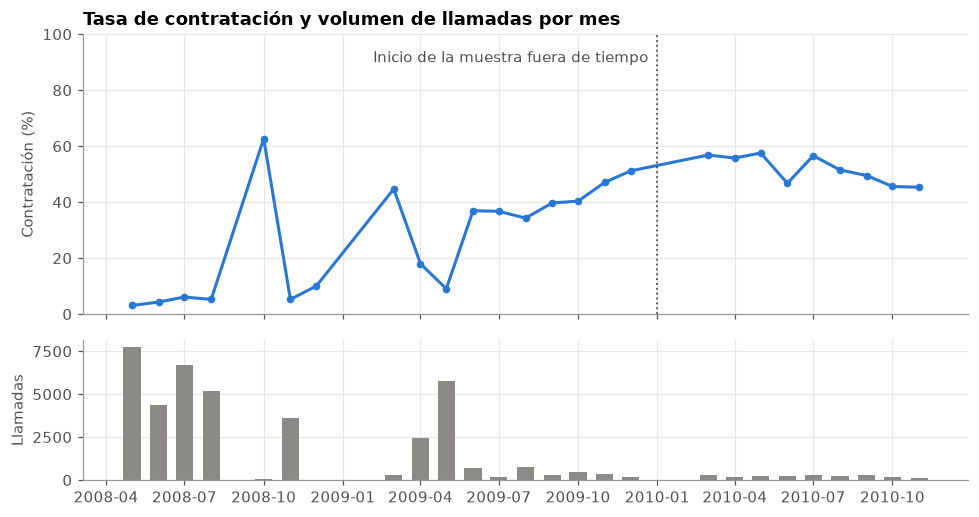

,Rol,Filas,Tasa,Train expansiva,Train móvil 6m
Bloque evaluado,,,,,
2009-03 a 2009-05,Desarrollo,8532,12.8 %,27682,19920
2009-06 a 2009-09,Desarrollo,1929,36.2 %,36214,12224
2009-10 a 2009-12,Desarrollo,975,44.7 %,38143,10179
2010-01 a 2010-11,OOT,2058,52.1 %,39118,2189


In [ ]:
por_mes = df.groupby('periodo')['contrato'].agg(llamadas='size', tasa='mean')
fechas = por_mes.index.to_timestamp()
fig, (arriba, abajo) = plt.subplots(2, 1, figsize=(9, 4.8), sharex=True, height_ratios=[2, 1])
arriba.plot(fechas, por_mes['tasa'] * 100, color=AZUL, marker='o', markersize=4)
arriba.axvline(pd.Timestamp(INICIO_OOT), color=TINTA, linestyle=':', linewidth=1.2)
arriba.annotate('Inicio de la muestra fuera de tiempo', (pd.Timestamp(INICIO_OOT), 90), xytext=(-6, 0),
                textcoords='offset points', ha='right', color=TINTA)
arriba.set(ylabel='Contratación (%)', ylim=(0, 100), title='Tasa de contratación y volumen de llamadas por mes')
abajo.bar(fechas, por_mes['llamadas'], width=20, color=GRIS)
abajo.set_ylabel('Llamadas')
plt.tight_layout(); plt.show()


en_oot = (df['periodo'] >= pd.Period(INICIO_OOT, 'M')).to_numpy()
y_oot = y[en_oot]
filas = []
for d, h in BLOQUES_MODELAMIENTO + [(INICIO_OOT, '2010-11')]:
    te = mascara(d, h)
    filas.append({'Bloque evaluado': f'{d} a {h}', 'Rol': 'OOT' if d == INICIO_OOT else 'Desarrollo',
                  'Filas': int(te.sum()), 'Tasa': pct(y[te].mean()),
                  'Train expansiva': int(mascara_train(d, 'expansiva').sum()),
                  f'Train móvil {VENTANA_MOVIL}m': int(mascara_train(d, 'movil').sum())})
pd.DataFrame(filas).set_index('Bloque evaluado')

**Lectura.** La tasa pasa de cerca de 5 % en 2008 a más de 50 % en 2010, mientras las llamadas caen con fuerza. El cambio combina crisis económica y una probable modificación de a quién se llamaba. Es un quiebre estructural, y por eso comparamos ventanas. Los meses con pocas llamadas, como octubre de 2008, generan picos poco confiables.

## 4. Selección de variables

Una variable entra al modelo solo si aporta información, se mantiene estable y no repite lo que ya dicen las demás. Cada filtro se calcula **solo con la ventana de entrenamiento** de cada bloque, para no usar información del futuro. `duration` y `campaign` se excluyen desde el inicio porque solo se conocen durante o después de la llamada.

Los filtros se aplican en este orden:

| Paso | Métrica | Se descarta si | Pregunta que responde |
|---|---|---|---|
| 1 | Concentración | > 99 % | ¿La variable casi no varía? |
| 2 | Information Value (IV) | < 0.02 | ¿Ayuda a separar a quienes contratan? |
| 3 | Population Stability Index (PSI) | > 0.25 | ¿Su distribución cambió demasiado? |
| 4 | Correlación | > 0.70 | ¿Repite la información de otra variable? |
| 5 | Variance Inflation Factor (VIF) | > 5 | ¿Se puede explicar con varias variables juntas? |
| 6 | Signo del coeficiente | < 0 | ¿Su efecto contradice lo observado? |

### Weight of Evidence (WoE)

No es un filtro, pero es la base de varios de ellos. Convierte cada grupo de una variable en un número que resume su relación con la contratación:

$$WoE_i = \ln\left(\frac{\%\ \text{de los que contrataron en el grupo } i}{\%\ \text{de los que no contrataron en el grupo } i}\right)$$

Un WoE positivo indica un grupo con más propensión que el promedio. Las variables numéricas se dividen primero en cinco grupos, según sus quintiles.

### 1. Concentración

Es el porcentaje de observaciones que pertenece a la categoría más frecuente.

**Umbral: 99 %.** Es un criterio propio y deliberadamente laxo. En este problema, una categoría dominante puede ser muy informativa: la mayoría de las personas nunca fue contactada, y justamente quienes sí lo fueron son los que más contratan. Por eso solo se descarta una variable que casi no varía.

### 2. Information Value (IV)

Resume cuánto ayuda una variable a separar a quienes contratan de quienes no:

$$IV = \sum_i (\%\text{contrató}_i - \%\text{no contrató}_i) \times WoE_i$$

| IV | Lectura habitual |
|---|---|
| Menor a 0.02 | Sin poder predictivo útil |
| 0.02 a 0.10 | Débil |
| 0.10 a 0.30 | Medio |
| Mayor a 0.30 | Fuerte |

**Umbral: 0.02.** Es el punto de corte habitual en scorecards para señalar una variable sin poder predictivo útil.

### 3. Population Stability Index (PSI)

Compara la distribución de una variable en dos momentos. Aquí se compara la primera mitad de la ventana de entrenamiento con la segunda:

$$PSI = \sum_i (\%\text{nuevo}_i - \%\text{base}_i) \times \ln\left(\frac{\%\text{nuevo}_i}{\%\text{base}_i}\right)$$

| PSI | Lectura habitual |
|---|---|
| Hasta 0.10 | Estable |
| 0.10 a 0.25 | Cambio moderado; conviene revisar |
| Mayor a 0.25 | Cambio importante |

**Umbral: 0.25.** Es el límite habitual en monitoreo de modelos. Una variable cuya distribución cambia tanto puede funcionar en el entrenamiento y fallar más adelante.

### 4. Correlación

Mide con el coeficiente de Pearson, entre -1 y 1, si dos variables se mueven juntas. Se calcula sobre las variables en WoE, para comparar también las categóricas. Si dos variables superan el umbral, se conserva la de mayor IV.

**Umbral: 0.70.** Es una referencia usada en la literatura sobre colinealidad, a partir de la cual la distorsión de los coeficientes suele volverse relevante.

### 5. Variance Inflation Factor (VIF)

La correlación compara variables de a dos. El VIF detecta si una variable se puede explicar con **varias de las demás a la vez**:

$$VIF_j = \frac{1}{1 - R_j^2}$$

Donde $R_j^2$ indica qué parte de la variable $j$ se explica con el resto.

**Umbral: 5.** Equivale a que el 80 % de su variación ya está contenida en las otras variables. Si alguna lo supera, se elimina la de mayor VIF y se recalcula. Es una referencia orientativa y no una regla absoluta.

### 6. Coherencia de signo

Se ajusta una regresión logística con las variables en WoE. Como el WoE positivo indica mayor propensión, se espera un **coeficiente positivo**. Un coeficiente negativo contradice la relación que muestra la variable por sí sola, y suele ser señal de colinealidad.

**Umbral: 0.** Se elimina la variable con el coeficiente más negativo y se vuelve a ajustar, hasta que todos sean positivos.

### Por qué importa el orden

Primero se descarta lo que no aporta o no es estable. Después se compara lo que queda, para que la redundancia se resuelva entre variables que ya son útiles. Estos umbrales son puntos de partida: una excepción es válida si se justifica y se documenta.


### Ejemplo paso a paso: la variable `contact`

Veamos los cálculos con datos reales, usando la ventana móvil previa a 2010 (julio a diciembre de 2009, 2,189 llamadas).

| Canal | Contrataron | No contrataron | Tasa | % de los que contrataron | % de los que no contrataron | WoE |
|---|---|---|---|---|---|---|
| Celular | 796 | 1,144 | 41.0 % | 91.34 % | 86.77 % | +0.051 |
| Teléfono fijo | 75 | 174 | 30.1 % | 8.66 % | 13.23 % | −0.424 |

Los porcentajes incluyen un suavizado de 0.5 casos, que evita divisiones entre cero.

**WoE.** Para teléfono fijo: $\ln(0.0866 / 0.1323) = -0.424$. Es negativo porque ese grupo contrata menos.

**IV.** Sumamos el aporte de cada grupo:

$$(0.9134 - 0.8677)(0.051) + (0.0866 - 0.1323)(-0.424) = 0.0023 + 0.0194 = 0.0217$$

Supera apenas el mínimo de 0.02, así que la variable aporta poco por sí sola, pero pasa el filtro.

**PSI.** Comparamos ambas mitades de la ventana. El celular pasa de 89.76 % a 87.49 % y el fijo de 10.24 % a 12.51 %. El PSI es 0.005, muy por debajo de 0.25: la variable es estable.

**Cómo leer las tablas de abajo.** Cada fila es una variable. `motivo` indica el filtro que la eliminó, y las variables conservadas no tienen motivo. Compara ambas ventanas: una misma variable puede sobrevivir en una y caer en la otra.

In [18]:
def ajustar_bins(s, y_s):
    """Define grupos en la muestra de ajuste y calcula su WoE, con suavizado de 0.5 casos."""
    numerica = pd.api.types.is_numeric_dtype(s) and s.nunique() > 6
    cortes = np.unique(s.quantile([.2, .4, .6, .8]).to_numpy()) if numerica else None
    grupos = aplicar_bins(s, cortes)
    t = pd.DataFrame({'g': grupos.to_numpy(), 'y': y_s}).groupby('g')['y'].agg(['sum', 'size'])
    pos, neg = t['sum'] + 0.5, t['size'] - t['sum'] + 0.5
    p, q = pos / pos.sum(), neg / neg.sum()
    woe = np.log(p / q)  # WoE positivo: categoría con más propensión a contratar
    return cortes, woe, float(((p - q) * woe).sum())

def aplicar_bins(s, cortes):
    if cortes is None:
        return s.astype(str)
    return pd.cut(s, np.r_[-np.inf, cortes, np.inf], labels=False).astype(str)

def psi(g_base, g_nuevo):
    p, q = g_base.value_counts(normalize=True), g_nuevo.value_counts(normalize=True)
    i = p.index.union(q.index)
    p, q = p.reindex(i).fillna(0).clip(lower=1e-4), q.reindex(i).fillna(0).clip(lower=1e-4)
    return float(((p - q) * np.log(p / q)).sum())

class TransformadorWoE(BaseEstimator, TransformerMixin):
    def fit(self, X, y_x):
        self.reglas_ = {v: ajustar_bins(X[v], np.asarray(y_x))[:2] for v in X.columns}
        return self
    def transform(self, X):
        return np.column_stack([aplicar_bins(X[v], c).map(w).fillna(0).astype(float).to_numpy()
                                for v, (c, w) in self.reglas_.items()])

def seleccionar_variables(en_train, candidatas=POOL):
    """Aplica todos los filtros usando solo la ventana de entrenamiento."""
    tr = df.loc[en_train]
    y_tr, mitad, filas = y[en_train], len(tr) // 2, []
    for v in candidatas:
        cortes, woe, iv = ajustar_bins(tr[v], y_tr)
        g = aplicar_bins(tr[v], cortes)
        filas.append({'variable': v, 'IV': iv, 'PSI': psi(g.iloc[:mitad], g.iloc[mitad:]),
                      'concentración': g.value_counts(normalize=True).iloc[0]})
    t = pd.DataFrame(filas).set_index('variable')
    t['motivo'] = ''
    t.loc[t['concentración'] > CONCENTRACION_MAX, 'motivo'] = 'Concentración'
    t.loc[(t['motivo'] == '') & (t['IV'] < IV_MIN), 'motivo'] = 'IV bajo'
    t.loc[(t['motivo'] == '') & (t['PSI'] > PSI_MAX), 'motivo'] = 'PSI alto'
    vivas = list(t[t['motivo'] == ''].sort_values('IV', ascending=False).index)
    if not vivas:  # si todo cae, se conserva la variable más informativa
        vivas = [t['IV'].idxmax()]
        t.loc[vivas[0], 'motivo'] = ''
    Z = pd.DataFrame(TransformadorWoE().fit(tr[vivas], y_tr).transform(tr[vivas]), columns=vivas)
    corr, conservar = Z.corr().abs(), []
    for v in vivas:  # ordenadas por IV: entre dos correlacionadas sobrevive la de mayor IV
        if all(corr.loc[v, k] <= CORR_MAX for k in conservar):
            conservar.append(v)
        else:
            t.loc[v, 'motivo'] = 'Correlación'
    while len(conservar) > 2:
        vif = pd.Series(np.diag(np.linalg.pinv(Z[conservar].corr().to_numpy())), index=conservar)
        if vif.max() <= VIF_MAX:
            break
        peor = vif.idxmax()
        conservar.remove(peor)
        t.loc[peor, 'motivo'] = 'VIF'
    while len(conservar) > 1:  # con este WoE, un coeficiente negativo contradice la relación univariada
        coef = pd.Series(LogisticRegression(max_iter=3000).fit(Z[conservar], y_tr).coef_[0], index=conservar)
        if coef.min() > 0:
            break
        peor = coef.idxmin()
        conservar.remove(peor)
        t.loc[peor, 'motivo'] = 'Signo'
    t['estado'] = np.where(t.index.isin(conservar), 'Conservada', 'Descartada')
    return conservar, t

for ventana in ['expansiva', 'movil']:
    sel, tabla = seleccionar_variables(mascara_train(INICIO_OOT, ventana))
    print(f'\nVentana {ventana}, entrenando hasta 2009-12: {len(sel)} variables conservadas -> {sel}')
    display(tabla.round(3).sort_values(['estado', 'IV'], ascending=[True, False]))


Ventana expansiva, entrenando hasta 2009-12: 6 variables conservadas -> ['contactado_antes', 'job', 'default', 'age', 'education', 'marital']


,IV,PSI,concentración,motivo,estado
variable,,,,,
contactado_antes,0.280,0.243,0.980,,Conservada
job,0.129,0.100,0.250,,Conservada
default,0.089,0.135,0.781,,Conservada
age,0.063,0.017,0.221,,Conservada
education,0.032,0.102,0.291,,Conservada
marital,0.025,0.013,0.612,,Conservada
nr.employed,0.606,7.778,0.509,PSI alto,Descartada
emp.var.rate,0.579,5.594,0.415,PSI alto,Descartada
euribor3m,0.474,8.181,0.208,PSI alto,Descartada



Ventana movil, entrenando hasta 2009-12: 2 variables conservadas -> ['contactado_antes', 'contact']


,IV,PSI,concentración,motivo,estado
variable,,,,,
contactado_antes,0.261,0.028,0.795,,Conservada
contact,0.022,0.005,0.886,,Conservada
poutcome,0.255,0.030,0.578,Correlación,Descartada
previous,0.074,0.050,0.578,Signo,Descartada
cons.price.idx,0.052,14.611,0.352,PSI alto,Descartada
cons.conf.idx,0.052,14.611,0.352,PSI alto,Descartada
euribor3m,0.051,13.290,0.224,PSI alto,Descartada
emp.var.rate,0.043,10.303,0.489,PSI alto,Descartada
nr.employed,0.043,10.303,0.489,PSI alto,Descartada


**Lectura.** Todas las variables macro caen por PSI, pues cambian de régimen dentro de cualquier ventana. En la ventana móvil sobreviven `contactado_antes` y `contact`. `poutcome` se descarta por su correlación con `contactado_antes`, y `previous` por signo incoherente.

## 5. Comparación de campeón y retadores

Las 35 configuraciones cruzan estos elementos:

- **Algoritmos:** logística, logística con WoE tipo scorecard, Random Forest, XGBoost, LightGBM  y AutoML con FLAML, además de la regla simple como referencia.
- **Campeón:** Modelo de Regresion logística con todas las variables y todo el histórico
- **FLAML:** busca entre LightGBM, XGBoost, Random Forest, Extra Trees y logística. Se limita por iteraciones y con semilla fija, y valida con el 20 % más reciente de cada ventana.

**Regla de decisión, fijada de antemano.** Medimos `robusto = media(Gini) − desviación(Gini)` en los tres bloques. Entre las configuraciones a menos de 0.02 de la mejor, elegimos la más simple. Es una adaptación de la regla de un error estándar y limita el sesgo de elegir entre muchas alternativas. El Gini es `2 × AUC − 1`.

### Qué modelos compiten

| Modelo | Idea principal | A favor | En contra |
|---|---|---|---|
| **Regla simple** | Llamar primero a quien tuvo éxito antes | Fácil de explicar | Se agota cuando no quedan clientes con éxito previo |
| **Regresión logística** | Suma ponderada de variables convertida en probabilidad | Interpretable y estable | Capta menos relaciones complejas |
| **Logística con WoE** | Igual, pero cada variable se resume en WoE | Base de los scorecards | Depende de cómo se formen los grupos |
| **Random Forest** | Promedio de muchos árboles independientes | Capta interacciones | Menos interpretable |
| **XGBoost y LightGBM** | Árboles que corrigen los errores de los anteriores | Muy potentes en datos tabulares | Requieren más cuidado, y extrapolan mal |
| **FLAML (AutoML)** | Busca automáticamente algoritmo e hiperparámetros | Ahorra búsqueda manual | Puede sobreajustarse a la validación |

**Qué hacen las celdas siguientes**

- `crear` define cada algoritmo y su preparación de variables.
- `ajustar` entrena un modelo y devuelve una función para predecir.
- `CONFIGS` arma las combinaciones de algoritmo, ventana y conjunto de variables.
- `entrenar_config` entrena una combinación usando solo datos anteriores al bloque.
- `tasa_cupo` calcula la contratación dentro del cupo.
- La última celda evalúa todo y aplica la regla de decisión.

In [19]:
@dataclass
class Ajuste:
    variables: list
    modelo: object
    predecir: callable

def preparador(numericas, categoricas, escalar):
    pasos = []
    if numericas:
        pasos.append(('num', StandardScaler() if escalar else 'passthrough', numericas))
    if categoricas:
        pasos.append(('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categoricas))
    return ColumnTransformer(pasos)

def crear(algoritmo, numericas, categoricas):
    if algoritmo == 'logistica':
        return make_pipeline(preparador(numericas, categoricas, True), LogisticRegression(max_iter=3000))
    if algoritmo == 'woe':
        return make_pipeline(TransformadorWoE(), LogisticRegression(max_iter=3000))
    if algoritmo == 'rf':
        m = RandomForestClassifier(n_estimators=300, min_samples_leaf=25, max_features='sqrt',
                                   random_state=SEMILLA, n_jobs=-1)
    elif algoritmo == 'xgboost':
        m = XGBClassifier(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8, colsample_bytree=0.8,
                          reg_lambda=5, min_child_weight=20, eval_metric='logloss', random_state=SEMILLA, n_jobs=4)
    elif algoritmo == 'lightgbm':
        m = LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=7, min_child_samples=50, subsample=0.8,
                           subsample_freq=1, colsample_bytree=0.8, reg_lambda=5, random_state=SEMILLA,
                           n_jobs=1, deterministic=True, force_row_wise=True, verbose=-1)
    else:
        raise ValueError(algoritmo)
    return make_pipeline(preparador(numericas, categoricas, False), m)

def ajustar_flaml(numericas, categoricas, en_train, datos):
    """AutoML con una validación que también respeta el tiempo: el 20 % final de la ventana."""
    columnas = numericas + categoricas
    tr = datos.loc[en_train, columnas]
    y_tr = y[en_train]
    corte = int(len(tr) * 0.8)
    prep = preparador(numericas, categoricas, False).fit(tr.iloc[:corte])
    nombrar = lambda M: pd.DataFrame(M, columns=[f'f{i}' for i in range(M.shape[1])])
    automl = AutoML()
    automl.fit(X_train=nombrar(prep.transform(tr.iloc[:corte])), y_train=y_tr[:corte],
               X_val=nombrar(prep.transform(tr.iloc[corte:])), y_val=y_tr[corte:],
               task='classification', metric='roc_auc', eval_method='holdout',
               estimator_list=['lgbm', 'xgboost', 'rf', 'extra_tree', 'lrl2'],
               time_budget=-1, max_iter=FLAML_ITERACIONES, seed=SEMILLA, n_jobs=1, retrain_full=True, verbose=0)
    return Ajuste(columnas, automl, lambda d: automl.predict_proba(nombrar(prep.transform(d[columnas])))[:, 1])

def ajustar(algoritmo, numericas, categoricas, en_train, datos=None):
    datos = df if datos is None else datos
    if algoritmo == 'regla':
        return Ajuste(['exito_previo'], None, lambda d: d['exito_previo'].to_numpy().astype(float))
    if algoritmo == 'flaml':
        return ajustar_flaml(numericas, categoricas, en_train, datos)
    columnas = numericas + categoricas
    modelo = crear(algoritmo, numericas, categoricas).fit(datos.loc[en_train, columnas], y[en_train])
    return Ajuste(columnas, modelo, lambda d: modelo.predict_proba(d[columnas])[:, 1])

def separar(variables):
    return ([v for v in variables if pd.api.types.is_numeric_dtype(df[v])],
            [v for v in variables if not pd.api.types.is_numeric_dtype(df[v])])

In [20]:
CONJUNTOS = {'cliente': VARS_NUM + VARS_CLIENTE, 'completo': POOL, 'seleccionado': None}
ALGORITMOS = ['logistica', 'woe', 'rf', 'xgboost', 'lightgbm', 'flaml']
COMPLEJIDAD = dict(regla=0, logistica=1, woe=2, rf=3, xgboost=4, lightgbm=4, flaml=5)
REGLA = ('regla', 'sin entrenamiento', 'éxito previo')
CAMPEON = ('logistica', 'expansiva', 'completo')
CONFIGS = [REGLA] + [(a, v, s) for a in ALGORITMOS for v in ['expansiva', 'movil'] for s in CONJUNTOS
                     if not (a == 'flaml' and s == 'cliente')]
_cache_sel = {}

In [21]:
def variables_de(conjunto, inicio, ventana):
    if conjunto != 'seleccionado':
        return CONJUNTOS[conjunto]
    if (inicio, ventana) not in _cache_sel:
        _cache_sel[(inicio, ventana)] = seleccionar_variables(mascara_train(inicio, ventana))[0]
    return _cache_sel[(inicio, ventana)]

def entrenar_config(cfg, inicio):
    algoritmo, ventana, conjunto = cfg
    if algoritmo == 'regla':
        return ajustar('regla', [], [], None)
    n, k = separar(variables_de(conjunto, inicio, ventana))
    return ajustar(algoritmo, n, k, mascara_train(inicio, ventana))

def tasa_cupo(y_r, s, cupo, sorteos=50, semilla=SEMILLA):
    """Tasa de contratación en el cupo. Si hay empates, promedia varios sorteos."""
    rng = np.random.default_rng(semilla)
    k = max(1, int(len(s) * cupo))
    n_sorteos = 1 if len(np.unique(s)) == len(s) else sorteos
    return float(np.mean([y_r[np.lexsort((rng.random(len(s)), -s))[:k]].mean() for _ in range(n_sorteos)]))


In [ ]:

etiqueta = lambda cfg: ' | '.join(cfg)
filas = []
for inicio, hasta in BLOQUES_MODELAMIENTO:
    te = mascara(inicio, hasta)
    for cfg in CONFIGS:
        a = entrenar_config(cfg, inicio)
        s = a.predecir(df.loc[te])
        filas.append({'config': etiqueta(cfg), 'algoritmo': cfg[0], 'bloque': inicio, 'gini': gini(y[te], s),
                      'tasa_cupo': tasa_cupo(y[te], s, CUPO), 'n_variables': len(a.variables)})
res = pd.DataFrame(filas)

pivote = res.pivot(index='config', columns='bloque', values='gini')
resumen = pivote.assign(media=pivote.mean(axis=1), desv=pivote.std(axis=1))
resumen['robusto'] = resumen['media'] - resumen['desv']
resumen['tasa_cupo'] = res.groupby('config')['tasa_cupo'].mean()
resumen['n_variables'] = res.groupby('config')['n_variables'].mean().round(1)
resumen['algoritmo'] = res.groupby('config')['algoritmo'].first()
resumen['complejidad'] = resumen['algoritmo'].map(COMPLEJIDAD)
resumen = resumen.sort_values('robusto', ascending=False)

mejor = resumen['robusto'].max()
elegibles = resumen[resumen['robusto'] >= mejor - TOLERANCIA_GINI].sort_values(['complejidad', 'n_variables', 'robusto'],
                                                                                 ascending=[True, True, False])
GANADOR_ET = elegibles.index[0]
GANADOR = next(c for c in CONFIGS if etiqueta(c) == GANADOR_ET)
print(f'Mejor puntaje robusto: {resumen.index[0]} ({mejor:.3f})')
print(f'Dentro de la tolerancia de {TOLERANCIA_GINI}: {len(elegibles)} configuraciones')
print(f'Modelo elegido por la regla de parsimonia: {GANADOR_ET}')
def elegir_con_tolerancia(tol):
    e = resumen[resumen['robusto'] >= mejor - tol].sort_values(['complejidad', 'n_variables', 'robusto'], ascending=[True, True, False])
    return e.index[0]
print('\nSensibilidad de la elección a la tolerancia:')
display(pd.DataFrame({'Modelo elegido': {t_: elegir_con_tolerancia(t_) for t_ in [0.005, 0.01, 0.015, 0.02, 0.03]}}).rename_axis('Tolerancia'))
display(resumen.drop(columns=['algoritmo', 'complejidad']).head(15).round(3))
print('Referencias:')
display(resumen.loc[[etiqueta(REGLA), etiqueta(CAMPEON)]].drop(columns=['algoritmo', 'complejidad']).round(3))

Mejor puntaje robusto: woe | expansiva | completo (0.199)
Dentro de la tolerancia de 0.02: 6 configuraciones
Modelo elegido por la regla de parsimonia: logistica | movil | seleccionado

Sensibilidad de la elección a la tolerancia:


,Modelo elegido
Tolerancia,
0.005,woe | expansiva | completo
0.010,logistica | expansiva | completo
0.015,logistica | expansiva | completo
0.020,logistica | movil | seleccionado
0.030,logistica | movil | seleccionado


bloque,2009-03,2009-06,2009-10,media,desv,robusto,tasa_cupo,n_variables
config,,,,,,,,
woe | expansiva | completo,0.241,0.197,0.271,0.236,0.037,0.199,0.541,16.0
logistica | expansiva | completo,0.296,0.186,0.268,0.250,0.057,0.192,0.559,16.0
woe | movil | cliente,0.231,0.184,0.243,0.220,0.031,0.189,0.539,10.0
woe | movil | completo,0.231,0.189,0.285,0.235,0.048,0.187,0.535,16.0
lightgbm | movil | completo,0.180,0.219,0.232,0.210,0.027,0.183,0.490,16.0
logistica | movil | seleccionado,0.251,0.178,0.217,0.216,0.036,0.179,0.552,4.3
woe | expansiva | cliente,0.254,0.170,0.263,0.229,0.052,0.177,0.554,10.0
logistica | movil | cliente,0.183,0.173,0.250,0.202,0.042,0.160,0.521,10.0
logistica | expansiva | cliente,0.213,0.159,0.259,0.210,0.050,0.160,0.536,10.0


Referencias:


bloque,2009-03,2009-06,2009-10,media,desv,robusto,tasa_cupo,n_variables
config,,,,,,,,
regla | sin entrenamiento | éxito previo,0.062,0.149,0.213,0.141,0.076,0.065,0.498,1.0
logistica | expansiva | completo,0.296,0.186,0.268,0.250,0.057,0.192,0.559,16.0


### Cómo leer esta tabla y cómo se eligió el modelo

Cada configuración se nombra `algoritmo | ventana | conjunto de variables`. Por ejemplo, `logistica | movil | seleccionado` es una regresión logística, entrenada con los últimos 6 meses y con las variables que pasaron los filtros.

Las columnas `2009-03`, `2009-06` y `2009-10` muestran el Gini de cada bloque. `media` es su promedio, `desv` indica cuánto varía, y `robusto` es la media menos la desviación: premia a los modelos buenos **y** estables.

**La regla aplicada, paso a paso**

1. El mejor puntaje robusto es 0.199.
2. Con una tolerancia de 0.02, quedan los modelos con puntaje de al menos 0.179. Son 6.
3. Entre ellos, se prefieren los de menor complejidad: las regresiones logísticas.
4. Hay dos logísticas: una con 16 variables y otra con 4.3 en promedio. Gana la de menos variables.

La tabla de tolerancias muestra que esta decisión no es absoluta. Elegir un modelo siempre incluye un juicio, y lo correcto es hacerlo visible.

**Lectura.** La regla de parsimonia elige la logística con ventana móvil y variables seleccionadas. La elección es **sensible a la tolerancia**: con 0.01 o 0.015 ganaría el campeón, y el modelo elegido queda justo en el límite de 0.02. Las diferencias entre los primeros puestos son pequeñas. Los modelos de árboles no superan a la logística en desarrollo, lo cual es coherente con una deriva que los árboles no extrapolan bien.

## 6. Evaluación fuera de tiempo

Evaluamos todas las configuraciones por transparencia, pero el resultado que cuenta es el del modelo elegido. Los intervalos provienen de un bootstrap pareado: todos los modelos se evalúan sobre las mismas remuestras.

### Cómo se mide el desempeño en la prueba final

| Métrica | Qué responde | Cómo leerla |
|---|---|---|
| **AUC** | ¿Qué tan seguido ordena bien a dos personas? | 0.5 es azar y 1 es perfecto |
| **Gini** | Lo mismo, en otra escala | 0 es azar y 1 es perfecto |
| **AP** (*Average Precision*) | ¿Qué tan bien concentra a quienes contratan al inicio de la lista? | Compárala con la tasa base, 0.521 |
| **Tasa en cupo** | ¿Cuántos contratan entre los llamados? | Es la métrica más cercana al negocio |

**Empates.** Con pocas variables, muchas personas reciben el mismo score. Si un empate cruza el límite del cupo, se promedian varios sorteos para no depender de uno solo.

**Bootstrap.** Solo tenemos una muestra de 2010, y otra muestra habría dado un resultado algo distinto. El bootstrap simula esa variación: toma 2,000 muestras con reemplazo de los mismos datos y recalcula la métrica en cada una. Entre los percentiles 2.5 y 97.5 queda el **intervalo de confianza del 95 %**.

Es **pareado** porque todos los modelos se evalúan con las mismas muestras. Si el intervalo de una diferencia no incluye el cero, la diferencia es difícil de atribuir al azar.

In [23]:
ajustes = {cfg: entrenar_config(cfg, INICIO_OOT) for cfg in CONFIGS}
scores = {cfg: ajustes[cfg].predecir(df.loc[en_oot]) for cfg in CONFIGS}

tabla_oot = pd.DataFrame([{
    'config': etiqueta(cfg), 'Gini OOT': gini(y_oot, scores[cfg]), 'AUC': roc_auc_score(y_oot, scores[cfg]),
    'AP': average_precision_score(y_oot, scores[cfg]), 'Tasa en cupo': tasa_cupo(y_oot, scores[cfg], CUPO),
    'Variables': len(ajustes[cfg].variables),
    'Gini desarrollo': resumen.loc[etiqueta(cfg), 'media'],
} for cfg in CONFIGS]).set_index('config').sort_values('Gini OOT', ascending=False)

REFERENCIAS = list(dict.fromkeys([GANADOR, CAMPEON, REGLA]))
print(f'OOT: {len(y_oot):,} llamadas | tasa {pct(y_oot.mean())} | cupo {int(len(y_oot) * CUPO)} llamadas')
print(f'Modelo elegido antes de mirar OOT: {GANADOR_ET}')
print(f'Posición del elegido entre {len(CONFIGS)} configuraciones: {tabla_oot.index.get_loc(GANADOR_ET) + 1}')
display(tabla_oot.head(12).round(3))
display(tabla_oot.loc[[etiqueta(c) for c in REFERENCIAS]].round(3))

OOT: 2,058 llamadas | tasa 52.1 % | cupo 205 llamadas
Modelo elegido antes de mirar OOT: logistica | movil | seleccionado
Posición del elegido entre 35 configuraciones: 11


,Gini OOT,AUC,AP,Tasa en cupo,Variables,Gini desarrollo
config,,,,,,
logistica | expansiva | completo,0.437,0.719,0.715,0.780,16,0.250
rf | expansiva | completo,0.437,0.719,0.714,0.790,16,0.192
rf | movil | completo,0.433,0.716,0.716,0.795,16,0.188
woe | movil | completo,0.419,0.710,0.703,0.780,16,0.235
flaml | movil | completo,0.409,0.704,0.704,0.766,16,0.121
flaml | movil | seleccionado,0.404,0.702,0.666,0.756,2,0.130
lightgbm | movil | seleccionado,0.404,0.702,0.666,0.756,2,0.126
woe | movil | seleccionado,0.404,0.702,0.666,0.756,2,0.136
rf | movil | seleccionado,0.404,0.702,0.666,0.756,2,0.116


,Gini OOT,AUC,AP,Tasa en cupo,Variables,Gini desarrollo
config,,,,,,
logistica | movil | seleccionado,0.404,0.702,0.666,0.756,2,0.216
logistica | expansiva | completo,0.437,0.719,0.715,0.780,16,0.250
regla | sin entrenamiento | éxito previo,0.314,0.657,0.637,0.766,1,0.141


,Gini OOT,IC 95 % Gini,Tasa cupo,IC 95 % tasa
Modelo,,,,
logistica | movil | seleccionado,0.404,+0.362 a +0.443,75.6 %,69.8 % a 81.5 %
logistica | expansiva | completo,0.437,+0.392 a +0.481,78.0 %,72.2 % a 83.4 %
regla | sin entrenamiento | éxito previo,0.314,+0.278 a +0.351,76.6 %,71.2 % a 82.9 %


,Δ Gini (media),IC 95 %,Remuestreos en que gana el elegido
Comparación,,,
Elegido − logistica | expansiva | completo,-0.034,-0.059 a -0.009,0.4 %
Elegido − regla | sin entrenamiento | éxito previo,0.090,+0.065 a +0.114,100.0 %


,Filas,Tasa,logistica | movil | seleccionado,logistica | expansiva | completo,regla | sin entrenamiento | éxito previo
Bloque OOT,,,,,
2010-03 a 2010-06,879,54.2 %,0.351,0.381,0.282
2010-07 a 2010-11,1179,50.6 %,0.444,0.484,0.338


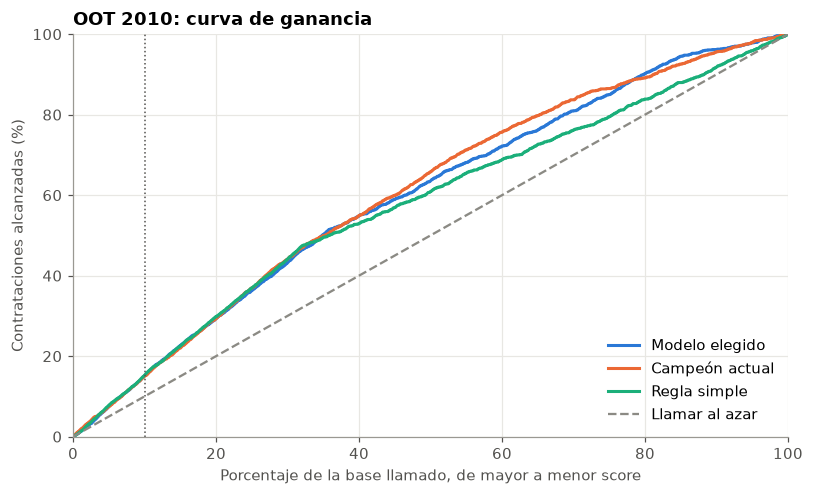

In [24]:
CUPOS = [0.05, 0.10, 0.20, 0.30, 0.50]

def bootstrap(y_r, dic, cupos, n=N_BOOTSTRAP, semilla=SEMILLA):
    """Remuestreo pareado: todos los modelos se evalúan sobre las mismas muestras."""
    rng = np.random.default_rng(semilla)
    total = len(y_r)
    ks = [max(1, int(total * c)) for c in cupos]
    g = {k: np.empty(n) for k in dic}
    t = {k: np.empty((n, len(cupos))) for k in dic}
    for b in range(n):
        idx = rng.integers(0, total, total)
        yb = y_r[idx]
        for k, s in dic.items():
            g[k][b] = gini(yb, s[idx])
            acum = np.cumsum(yb[np.lexsort((rng.random(total), -s[idx]))])
            t[k][b] = [acum[q - 1] / q for q in ks]
    return g, t

g_boot, t_boot = bootstrap(y_oot, {c: scores[c] for c in REFERENCIAS}, CUPOS)
ic = lambda v, f=1: f'{f * np.percentile(v, 2.5):+.3f} a {f * np.percentile(v, 97.5):+.3f}'
i10 = CUPOS.index(CUPO)

filas = [{'Modelo': etiqueta(c), 'Gini OOT': round(gini(y_oot, scores[c]), 3), 'IC 95 % Gini': ic(g_boot[c]),
          'Tasa cupo': pct(tasa_cupo(y_oot, scores[c], CUPO)),
          'IC 95 % tasa': f'{pct(np.percentile(t_boot[c][:, i10], 2.5))} a {pct(np.percentile(t_boot[c][:, i10], 97.5))}'}
         for c in REFERENCIAS]
display(pd.DataFrame(filas).set_index('Modelo'))

filas = []
for rival in [c for c in REFERENCIAS if c != GANADOR]:
    d = g_boot[GANADOR] - g_boot[rival]
    filas.append({'Comparación': f'Elegido − {etiqueta(rival)}', 'Δ Gini (media)': round(d.mean(), 3), 'IC 95 %': ic(d),
                  'Remuestreos en que gana el elegido': pct((d > 0).mean())})
if filas:
    display(pd.DataFrame(filas).set_index('Comparación'))
else:
    print('El modelo elegido coincide con el campeón y con la referencia comparada.')

por_bloque = []
for d_, h_ in [('2010-03', '2010-06'), ('2010-07', '2010-11')]:
    m_ = mascara(d_, h_)[en_oot]
    por_bloque.append({'Bloque OOT': f'{d_} a {h_}', 'Filas': int(m_.sum()), 'Tasa': pct(y_oot[m_].mean()),
                       **{etiqueta(c): round(gini(y_oot[m_], scores[c][m_]), 3) for c in REFERENCIAS}})
display(pd.DataFrame(por_bloque).set_index('Bloque OOT'))

fig, ax = plt.subplots(figsize=(7.5, 4.6))
for cfg, color, nombre in zip(REFERENCIAS, [AZUL, NARANJA, VERDE], ['Modelo elegido', 'Campeón actual', 'Regla simple']):
    orden = np.lexsort((np.random.default_rng(SEMILLA).random(len(y_oot)), -scores[cfg]))
    ax.plot(np.arange(1, len(y_oot) + 1) / len(y_oot) * 100, np.cumsum(y_oot[orden]) / y_oot.sum() * 100, color=color,
            label=etiqueta(cfg) if len(REFERENCIAS) < 3 else nombre)
ax.plot([0, 100], [0, 100], color=GRIS, linestyle='--', linewidth=1.5, label='Llamar al azar')
ax.axvline(CUPO * 100, color=TINTA, linewidth=1, linestyle=':')
ax.set(xlabel='Porcentaje de la base llamado, de mayor a menor score', ylabel='Contrataciones alcanzadas (%)',
       title='OOT 2010: curva de ganancia', xlim=(0, 100), ylim=(0, 100))
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

### Cómo leer la curva de ganancia

El eje horizontal indica a qué parte de la base llamamos, de mayor a menor score. El eje vertical indica qué parte de todas las contrataciones alcanzamos. La diagonal representa llamar al azar, y cuanto más arriba esté una curva, mejor. La línea punteada marca el cupo de 10 %.

**Ejemplo de lift.** Con el cupo de 10 %, el modelo elegido obtiene 75.6 % de contratación, frente a 52.1 % al azar: `75.6 / 52.1 = 1.45` veces mejor. Parece poco, pero como la tasa base es alta, el máximo posible es `1 / 0.521 = 1.92` veces. **Un lift siempre debe leerse junto con su máximo.**

**Lectura.**

- **El campeón supera al elegido** por 0.034 de Gini, y el intervalo de esa diferencia excluye el cero (−0.059 a −0.009).
- **El elegido supera a la regla** en 0.090 de Gini (0.065 a 0.114).
- **Todas las variantes con las mismas dos variables obtienen el mismo Gini**, 0.404. Con dos variables binarias hay solo cuatro segmentos, y cualquier algoritmo los ordena igual.
- **El Gini OOT es mayor que el de desarrollo** (0.404 frente a 0.216). En 2010 hay muchas más personas con contacto previo, y eso aumenta la separación. No debe leerse como una mejora del modelo.

## 7. Calibración

Un modelo puede ordenar bien y tener probabilidades equivocadas. Ajustamos el nivel con un desplazamiento en escala logit, que corrige un cambio en la tasa base sin alterar el orden dentro de cada mes. Para cada mes usamos solo los 3 meses anteriores con datos.

### Ordenar no es lo mismo que acertar la probabilidad

Un modelo puede poner primero a las personas correctas y, aun así, decir que tienen 30 % de probabilidad cuando en realidad tienen 50 %. Para elegir a quién llamar basta el orden. Para estimar cuántas contrataciones esperar se necesitan probabilidades correctas.

**Cómo se corrige.** Un logit transforma una probabilidad a una escala sin límites: $\text{logit}(p) = \ln\left(\frac{p}{1-p}\right)$. Sumamos la misma constante a todos los logits hasta que el promedio predicho coincida con la tasa de los 3 meses previos. Como todos se mueven por igual, **el orden dentro del mes no cambia**. En 2010, ese ajuste fue cercano a +0.4: una persona con 64.5 % pasa a alrededor de 73.2 %.

**Cómo se mide**

| Métrica | Cálculo | Lectura |
|---|---|---|
| **Brier** | Promedio de $(p - y)^2$ | Menor es mejor. Predecir 50 % para todos da 0.25 |
| **Log loss** | Penaliza con fuerza los errores muy confiados | Menor es mejor |

Por ejemplo, si el modelo predice 0.7 y la persona contrata, el error de Brier es $(0.7 - 1)^2 = 0.09$. Si no contrata, es $(0.7 - 0)^2 = 0.49$.

**Cómo leer el gráfico.** Cada punto agrupa un quinto de las personas. Si está sobre la diagonal, lo predicho coincide con lo observado. Por encima, el modelo subestima.

,Promedio predicho,Tasa real,Brier,Log loss
Enfoque,,,,
Modelo sin recalibrar,43.7 %,52.1 %,0.2251,0.6419
Tasa reciente para todos,52.1 %,52.1 %,0.2516,0.6964
Modelo recalibrado,52.8 %,52.1 %,0.2189,0.6287


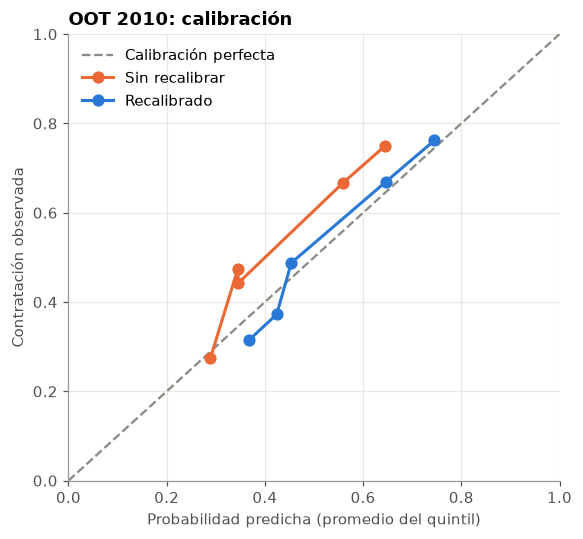

PSI del score, entrenamiento frente a OOT: 0.175


In [25]:
aj = ajustes[GANADOR]
p_todas = aj.predecir(df)

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

def sigmoide(x):
    return 1 / (1 + np.exp(-x))

def desplazamiento(p, objetivo):
    a, b, base = -10.0, 10.0, logit(p)
    for _ in range(60):
        m = (a + b) / 2
        a, b = (m, b) if sigmoide(base + m).mean() < objetivo else (a, m)
    return (a + b) / 2

meses_datos = np.array(sorted(df['periodo'].unique()))
bruta, recal, constante, y_ord = [], [], [], []
for mes in sorted(df.loc[en_oot, 'periodo'].unique()):
    previos = meses_datos[meses_datos < mes][-VENTANA_RECALIBRACION:]
    en_v, en_m = df['periodo'].isin(previos).to_numpy(), (df['periodo'] == mes).to_numpy()
    tasa = y[en_v].mean()
    delta = desplazamiento(p_todas[en_v], tasa)
    bruta.append(p_todas[en_m]); recal.append(sigmoide(logit(p_todas[en_m]) + delta))
    constante.append(np.full(en_m.sum(), tasa)); y_ord.append(y[en_m])
bruta, recal, constante, y_ord = map(np.concatenate, (bruta, recal, constante, y_ord))

filas = [{'Enfoque': n, 'Promedio predicho': pct(p.mean()), 'Tasa real': pct(y_ord.mean()),
          'Brier': round(brier_score_loss(y_ord, p), 4), 'Log loss': round(log_loss(y_ord, p), 4)}
         for n, p in [('Modelo sin recalibrar', bruta), ('Tasa reciente para todos', constante), ('Modelo recalibrado', recal)]]
display(pd.DataFrame(filas).set_index('Enfoque'))

def puntos(y_r, p, grupos=5):
    g = pd.qcut(pd.Series(p).rank(method='first'), grupos, labels=False)
    t = pd.DataFrame({'y': y_r, 'p': p, 'g': g}).groupby('g').mean()
    return t['p'], t['y']

fig, ax = plt.subplots(figsize=(5.4, 5))
ax.plot([0, 1], [0, 1], color=GRIS, linestyle='--', linewidth=1.5, label='Calibración perfecta')
for p, color, n in [(bruta, NARANJA, 'Sin recalibrar'), (recal, AZUL, 'Recalibrado')]:
    x_, o_ = puntos(y_ord, p)
    ax.plot(x_, o_, color=color, marker='o', markersize=7, label=n)
ax.set(xlabel='Probabilidad predicha (promedio del quintil)', ylabel='Contratación observada',
       title='OOT 2010: calibración', xlim=(0, 1), ylim=(0, 1))
ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

en_train_g = mascara_train(INICIO_OOT, GANADOR[1]) if GANADOR[0] != 'regla' else (df['periodo'] < pd.Period(INICIO_OOT, 'M')).to_numpy()
cortes_s = np.unique(np.quantile(p_todas[en_train_g], np.arange(.1, 1, .1)))
gs = lambda m: pd.Series(np.digitize(p_todas[m], cortes_s))
print(f'PSI del score, entrenamiento frente a OOT: {psi(gs(en_train_g), gs(en_oot)):.3f}')

**Lectura.** Sin recalibrar, el promedio predicho es 43.7 % frente a una tasa real de 52.1 %. La recalibración lo lleva a 52.8 % y reduce el Brier de 0.2251 a 0.2189. Ambas versiones superan a la referencia que asigna la tasa reciente a todos (0.2516). El PSI del score es 0.175: un cambio moderado que amerita seguimiento.

## 8. Análisis de sensibilidad

Probamos cuatro cosas: el contraste con validación cruzada aleatoria, la longitud de la ventana, el retiro de grupos de variables y un estrés de los indicadores macro. Estas pruebas no se usan para volver a elegir el modelo.

### Qué prueba cada análisis

Un resultado robusto no debería depender de un detalle. La celda siguiente hace cuatro preguntas:

1. **¿Cambia si validamos al azar?** La validación cruzada divide los datos en 10 partes aleatorias. `Q1` es el valor que deja por debajo al 25 % de los resultados, una lectura más conservadora que el promedio.
2. **¿Depende de cuántos meses usamos para entrenar?** Probamos ventanas de 3, 6, 9 y 12 meses, y todo el histórico.
3. **¿De qué información depende?** Retiramos un grupo de variables cada vez y medimos cuánto cae el Gini.
4. **¿Qué pasa si fallan los indicadores macro?** Simulamos que llegan con un mes de rezago y aplicamos choques de una desviación estándar. `Top coincidente` indica cuántas personas del top original siguen seleccionadas.

Estas pruebas buscan los puntos débiles del modelo. Por eso no se usan para volver a elegirlo.

In [26]:
assert GANADOR[0] != 'regla', 'Las pruebas de sensibilidad requieren un modelo con variables'
alg_s = 'logistica' if GANADOR[0] == 'flaml' else GANADOR[0]
vars_g = ajustes[GANADOR].variables
base_gini = gini(y_oot, scores[GANADOR])

# 1. Contraste con validación cruzada aleatoria de 10 particiones
n_, k_ = separar(vars_g)
ginis_cv = []
for tr_, te_ in StratifiedKFold(10, shuffle=True, random_state=SEMILLA).split(df, y):
    m_tr = np.zeros(len(df), dtype=bool); m_tr[tr_] = True
    ginis_cv.append(gini(y[te_], ajustar(alg_s, n_, k_, m_tr).predecir(df.iloc[te_])))
print('1. Validación cruzada aleatoria (10 particiones)')
print(f'   Gini medio {np.mean(ginis_cv):.3f} | Q1 {np.percentile(ginis_cv, 25):.3f} | desviación {np.std(ginis_cv):.3f}')
print(f'   Gini temporal: desarrollo {resumen.loc[GANADOR_ET, "media"]:.3f} | OOT {base_gini:.3f}')

# 2. Longitud de la ventana de entrenamiento
filas = []
for meses in [3, 6, 9, 12, None]:
    previos = sorted(df.loc[df['periodo'] < pd.Period(INICIO_OOT, 'M'), 'periodo'].unique())
    m_tr = df['periodo'].isin(previos if meses is None else previos[-meses:]).to_numpy()
    aj_v = ajustar(alg_s, n_, k_, m_tr)
    filas.append({'Ventana': 'Todo el histórico' if meses is None else f'{meses} meses con datos', 'Filas': int(m_tr.sum()),
                  'Tasa train': pct(y[m_tr].mean()), 'Gini OOT': round(gini(y_oot, aj_v.predecir(df.loc[en_oot])), 3)})
print('\n2. Sensibilidad a la ventana de entrenamiento')
display(pd.DataFrame(filas).set_index('Ventana'))

# 3. Retirar grupos de variables
GRUPOS = {'Historial': ['previous', 'contactado_antes', 'poutcome'], 'Canal': ['contact'], 'Macro': MACRO,
          'Demográficas': ['age', 'job', 'marital', 'education'], 'Productos y mora': ['default', 'housing', 'loan']}
en_tr_g = mascara_train(INICIO_OOT, GANADOR[1])
filas = [{'Escenario': 'Modelo elegido', 'Variables': len(vars_g), 'Gini OOT': round(base_gini, 3), 'Cambio': ''}]
for nombre, grupo in GRUPOS.items():
    resto = [v for v in vars_g if v not in grupo]
    if len(resto) == len(vars_g):
        filas.append({'Escenario': f'Sin {nombre}', 'Variables': len(resto), 'Gini OOT': '', 'Cambio': 'No está en el modelo'})
        continue
    if not resto:
        continue
    n2, k2 = separar(resto)
    g2 = gini(y_oot, ajustar(alg_s, n2, k2, en_tr_g).predecir(df.loc[en_oot]))
    filas.append({'Escenario': f'Sin {nombre}', 'Variables': len(resto), 'Gini OOT': round(g2, 3), 'Cambio': f'{g2 - base_gini:+.3f}'})
_, tabla_g = seleccionar_variables(en_tr_g)
por_signo = list(tabla_g.index[tabla_g['motivo'] == 'Signo'])
if por_signo:
    n4, k4 = separar(vars_g + por_signo)
    g4 = gini(y_oot, ajustar(alg_s, n4, k4, en_tr_g).predecir(df.loc[en_oot]))
    filas.append({'Escenario': 'Con ' + ', '.join(por_signo) + ' (descartada por signo)', 'Variables': len(vars_g) + len(por_signo),
                  'Gini OOT': round(g4, 3), 'Cambio': f'{g4 - base_gini:+.3f}'})
print('3. Retiro de grupos de variables')
display(pd.DataFrame(filas).set_index('Escenario'))

# 4. Estrés sobre las variables macro: rezago de un mes y choques de ±1 desviación estándar
ref_macro = GANADOR if any(v in MACRO for v in vars_g) else CAMPEON
alg_m = 'logistica' if ref_macro[0] == 'flaml' else ref_macro[0]
aj_m, vars_m = ajustes[ref_macro], [v for v in ajustes[ref_macro].variables if v in MACRO]
en_tr_m, s_b = mascara_train(INICIO_OOT, ref_macro[1]), scores[ref_macro]
k_top = int(len(y_oot) * CUPO)
top_b = set(np.argsort(-s_b, kind='stable')[:k_top])
filas = [{'Escenario': 'Base', 'Gini OOT': round(gini(y_oot, s_b), 3), 'Score medio': pct(s_b.mean()), 'Top coincidente': '100.0 %'}]
n3, k3 = separar(aj_m.variables)
rez = df.copy()
por_periodo = df.groupby('periodo')[vars_m].mean()
for v in vars_m:
    rez[v] = df['periodo'].map(por_periodo[v].shift(1).bfill()).to_numpy()
s_r = ajustar(alg_m, n3, k3, en_tr_m, datos=rez).predecir(rez.loc[en_oot])
filas.append({'Escenario': 'Macro con un mes de rezago', 'Gini OOT': round(gini(y_oot, s_r), 3), 'Score medio': pct(s_r.mean()),
              'Top coincidente': pct(len(top_b & set(np.argsort(-s_r, kind='stable')[:k_top])) / k_top)})
for signo in [1, -1]:
    d_e = df.loc[en_oot].copy()
    d_e[vars_m] = d_e[vars_m] + signo * df.loc[en_tr_m, vars_m].std()
    s_e = aj_m.predecir(d_e)
    filas.append({'Escenario': f'Macro {signo:+d} desviación estándar', 'Gini OOT': round(gini(y_oot, s_e), 3), 'Score medio': pct(s_e.mean()),
                  'Top coincidente': pct(len(top_b & set(np.argsort(-s_e, kind='stable')[:k_top])) / k_top)})
print(f'4. Estrés macro sobre: {etiqueta(ref_macro)}')
display(pd.DataFrame(filas).set_index('Escenario'))

1. Validación cruzada aleatoria (10 particiones)
   Gini medio 0.349 | Q1 0.331 | desviación 0.022
   Gini temporal: desarrollo 0.216 | OOT 0.404

2. Sensibilidad a la ventana de entrenamiento


,Filas,Tasa train,Gini OOT
Ventana,,,
3 meses con datos,975,44.7 %,0.404
6 meses con datos,2189,39.8 %,0.404
9 meses con datos,11154,18.8 %,0.404
12 meses con datos,15061,16.1 %,0.404
Todo el histórico,39118,9.1 %,0.404


3. Retiro de grupos de variables


,Variables,Gini OOT,Cambio
Escenario,,,
Modelo elegido,2,0.404,
Sin Historial,1,0.18,-0.224
Sin Canal,1,0.319,-0.085
Sin Macro,2,,No está en el modelo
Sin Demográficas,2,,No está en el modelo
Sin Productos y mora,2,,No está en el modelo
Con previous (descartada por signo),3,0.465,+0.061


4. Estrés macro sobre: logistica | expansiva | completo


,Gini OOT,Score medio,Top coincidente
Escenario,,,
Base,0.437,32.3 %,100.0 %
Macro con un mes de rezago,0.376,13.6 %,27.8 %
Macro +1 desviación estándar,0.437,25.2 %,100.0 %
Macro -1 desviación estándar,0.437,40.2 %,100.0 %


**Lectura.**

1. **Validación aleatoria.** Da un Gini de 0.349 con un primer cuartil de 0.331. Mezcla regímenes, así que sirve como contraste y no reemplaza la evaluación temporal.
2. **Ventana.** El Gini OOT es igual para todas las longitudes porque cuatro segmentos conservan su orden. Esa invariancia es la principal fortaleza del modelo.
3. **Variables.** El historial aporta más que el canal. La variable `previous`, descartada por signo, habría elevado el Gini OOT a 0.465. **No la reincorporamos**: hacerlo sería ajustar el modelo mirando la prueba final.
4. **Estrés macro sobre el campeón.** Con un mes de rezago, su Gini cae de 0.437 a 0.376 y su score medio pasa de 32.3 % a 13.6 %. Con esa pérdida, queda por debajo del modelo elegido. Los choques de ±1 desviación estándar mueven el nivel, pero no el orden, porque afectan a todos por igual.

## 9. Interpretabilidad y equidad

Revisamos el modelo elegido como tabla de segmentos, los pesos de la logística completa y los valores SHAP de XGBoost  para contrastar qué variables usa un modelo complejo. Después hacemos una comparación descriptiva por edad y estado civil.

### Cómo interpretar los resultados de esta sección

**Tabla de segmentos.** Con dos variables binarias, el modelo equivale a cuatro grupos, y se puede explicar sin fórmulas.

**Odds ratio.** Las chances son `p / (1 − p)`, y el odds ratio compara las chances de dos grupos. Por ejemplo, `contact: telephone frente a cellular = 0.63` significa que quienes tienen teléfono fijo presentan chances 37 % menores, manteniendo igual el resto de variables. Un valor de 1 indica que no hay diferencia.

**Signo coherente.** Con nuestro WoE, un coeficiente positivo es lo esperado. Si fuera negativo, el modelo contradiría lo que la variable muestra por sí sola.

**SHAP.** Reparte cada predicción entre las variables, como si cada una aportara una parte del resultado. Promediando esos aportes en valor absoluto, vemos cuánto usa cada variable un modelo complejo.

**Equidad.** Comparamos resultados por edad y estado civil, porque un modelo puede funcionar peor o seleccionar menos a ciertos grupos. `Seleccionados en el top` debería acercarse al cupo de 10 %. No usar una variable sensible no garantiza por sí solo un resultado equitativo, ya que otras variables pueden estar relacionadas con ella.

In [27]:
# El modelo elegido, si es pequeño, se puede leer como una tabla de segmentos
assert np.array_equal(y_ord, y_oot)
if len(vars_g) <= 3:
    seg = df.loc[en_oot, vars_g].assign(y=y_oot, bruto=scores[GANADOR], recal=recal)
    tab = seg.groupby(vars_g).agg(personas=('y', 'size'), bruto=('bruto', 'mean'), recal=('recal', 'mean'), observado=('y', 'mean'))
    tab = tab.sort_values('recal', ascending=False)
    print('Segmentos del modelo elegido en OOT (probabilidades promedio)')
    display(tab.assign(bruto=tab['bruto'].map(pct), recal=tab['recal'].map(pct), observado=tab['observado'].map(pct))
            .rename(columns={'personas': 'Personas', 'bruto': 'Predicho sin recalibrar', 'recal': 'Predicho recalibrado', 'observado': 'Observado'}))

# Regresión logística: contraste de cada categoría frente a la más frecuente
vent = GANADOR[1] if GANADOR[1] in ('expansiva', 'movil') else 'expansiva'
aj_lr = ajustes[('logistica', vent, 'completo')]
pipe = aj_lr.modelo
nombres = [n.split('__', 1)[1] for n in pipe.steps[0][1].get_feature_names_out()]
pesos = pd.Series(pipe.steps[-1][1].coef_[0], index=nombres)
en_tr_i = mascara_train(INICIO_OOT, vent)
filas = [{'Comparación': f'{v}: +1 desviación estándar', 'peso': pesos[v]} for v in VARS_NUM]
for v in VARS_CLIENTE + ['contact']:
    f_ = df.loc[en_tr_i, v].value_counts()
    filas += [{'Comparación': f'{v}: {cat} frente a {f_.index[0]}', 'peso': pesos[f'{v}_{cat}'] - pesos[f'{v}_{f_.index[0]}']}
              for cat, n in f_.items() if cat != f_.index[0] and n >= 100]
cont = pd.DataFrame(filas).set_index('Comparación')['peso']
print(f'Logística ({vent}, completo): odds ratio de cliente, historial y canal')
display(pd.DataFrame({'odds ratio': np.exp(pd.concat([cont.nlargest(6), cont.nsmallest(6)])).round(2)}))

# Coherencia de signos en el scorecard: con este WoE se espera coeficiente positivo
aj_w = ajustes[('woe', vent, 'seleccionado')]
cw = pd.Series(aj_w.modelo.steps[-1][1].coef_[0], index=list(aj_w.modelo.steps[0][1].reglas_))
display(pd.DataFrame({'coeficiente WoE': cw.round(3), 'signo coherente': np.where(cw > 0, 'Sí', 'No')}).sort_values('coeficiente WoE', ascending=False))

# XGBoost: valores SHAP exactos para árboles, agrupados por variable original
aj_x = ajustes[('xgboost', vent, 'completo')]
prep_x, xgb = aj_x.modelo.steps[0][1], aj_x.modelo.steps[-1][1]
Xo = prep_x.transform(df.loc[en_oot, aj_x.variables])
contrib = xgb.get_booster().predict(DMatrix(Xo), pred_contribs=True)[:, :-1]
n_x = [n.split('__', 1)[1] for n in prep_x.get_feature_names_out()]
origen = [next((v for v in aj_x.variables if n == v or n.startswith(v + '_')), n) for n in n_x]
imp = pd.DataFrame(np.abs(contrib), columns=n_x).T.groupby(origen).sum().T.mean().sort_values(ascending=False)
print(f'XGBoost ({vent}, completo): participación de cada variable en |SHAP| medio')
display(pd.DataFrame({'participación': (imp / imp.sum()).map(pct)}))

# Equidad descriptiva en OOT
oot = df.loc[en_oot, ['age', 'marital']].copy()
oot['y'], oot['s'] = y_oot, scores[GANADOR]
orden_oot = np.lexsort((np.random.default_rng(SEMILLA).random(len(oot)), -oot['s'].to_numpy()))
oot['top'] = np.isin(np.arange(len(oot)), orden_oot[:int(len(oot) * CUPO)])
oot['edad'] = pd.cut(oot['age'], [0, 29, 59, 200], labels=['Hasta 29', '30 a 59', '60 o más'])
filas = []
for columna in ['edad', 'marital']:
    for valor, g_ in oot.groupby(columna, observed=True):
        if len(g_) < 30:
            continue
        filas.append({'Grupo': f'{columna}: {valor}', 'Personas': len(g_), 'Tasa real': pct(g_['y'].mean()),
                      'Seleccionados en el top': pct(g_['top'].mean()), 'Gini': round(gini(g_['y'], g_['s']), 3)})
display(pd.DataFrame(filas).set_index('Grupo'))

Segmentos del modelo elegido en OOT (probabilidades promedio)


Personas Predicho sin recalibrar Predicho recalibrado Observado
contactado_antes contact                                                                   
1                cellular        652                  64.5 %               73.2 %    75.8 %
                 telephone        73                  56.3 %               65.7 %    65.8 %
0                cellular       1018                  34.5 %               43.8 %    46.1 %
                 telephone       315                  27.2 %               36.5 %    19.7 %

Logística (movil, completo): odds ratio de cliente, historial y canal


,odds ratio
Comparación,
education: professional.course frente a university.degree,1.63
poutcome: success frente a nonexistent,1.54
education: basic.4y frente a university.degree,1.51
contactado_antes: +1 desviación estándar,1.47
education: unknown frente a university.degree,1.40
education: high.school frente a university.degree,1.22
job: blue-collar frente a admin.,0.56
contact: telephone frente a cellular,0.63
job: student frente a admin.,0.76


,coeficiente WoE,signo coherente
contactado_antes,0.979,Sí
contact,0.674,Sí


XGBoost (movil, completo): participación de cada variable en |SHAP| medio


,participación
euribor3m,21.6 %
contactado_antes,19.3 %
poutcome,15.1 %
education,9.6 %
job,7.8 %
age,6.8 %
contact,6.4 %
previous,2.9 %
marital,2.7 %
cons.price.idx,2.7 %


,Personas,Tasa real,Seleccionados en el top,Gini
Grupo,,,,
edad: Hasta 29,495,48.9 %,10.3 %,0.451
edad: 30 a 59,1218,52.0 %,9.3 %,0.407
edad: 60 o más,345,57.4 %,11.9 %,0.321
marital: divorced,222,56.3 %,5.4 %,0.454
marital: married,983,54.5 %,11.1 %,0.399
marital: single,850,48.2 %,9.8 %,0.403


**Lectura.**

- **Segmentos.** La mayor propensión está en quienes ya fueron contactados y tienen celular. La menor, en quienes nunca fueron contactados y tienen teléfono fijo.
- **Calibración por segmento.** En el segmento más bajo, la recalibración predice 36.5 % y se observa 19.7 %. Un solo ajuste de nivel no corrige errores que difieren entre segmentos, así que esa probabilidad no debe usarse sin revisión.
- **Modelo complejo.** XGBoost reparte su importancia entre `euribor3m`, `contactado_antes` y `poutcome`, y ninguna variable supera el 22 %. Su dependencia de `euribor3m` refuerza la cautela con las variables macro.
- **Equidad.** La selección en el top va de 5.4 % a 11.9 % entre grupos, y el Gini es menor en mayores de 60 años. Es una revisión descriptiva con grupos pequeños y no reemplaza un análisis formal de equidad. El modelo elegido no usa edad ni estado civil.

Estos pesos describen asociaciones entre personas que el banco decidió llamar. No son efectos causales.

## 10. Uso en la gestión

Traducimos el modelo a una tabla de decisión por cupo. El valor trata toda contratación observada como resultado de la llamada, algo que debe validarse con un experimento.

In [28]:
_, t_d = bootstrap(y_oot, {GANADOR: scores[GANADOR], REGLA: scores[REGLA]}, CUPOS, semilla=SEMILLA + 1)
filas = []
base = y_oot.mean()
for i, c_ in enumerate(CUPOS):
    k_ = int(len(y_oot) * c_)
    tm, tr_ = tasa_cupo(y_oot, scores[GANADOR], c_), tasa_cupo(y_oot, scores[REGLA], c_)
    dif = (t_d[GANADOR][:, i] - t_d[REGLA][:, i]) * 100
    cont_ = tm * k_
    filas.append({'Cupo': f'{c_:.0%}', 'Llamadas': k_, 'Tasa modelo': pct(tm),
                  'IC 95 %': f'{pct(np.percentile(t_d[GANADOR][:, i], 2.5))} a {pct(np.percentile(t_d[GANADOR][:, i], 97.5))}',
                  'Tasa regla': pct(tr_), 'Modelo − regla (puntos, IC 95 %)': f'{np.percentile(dif, 2.5):+.1f} a {np.percentile(dif, 97.5):+.1f}',
                  'Contrataciones': int(round(cont_)), 'Captura': pct(cont_ / y_oot.sum()),
                  'Valor modelo': int(round(cont_ * MARGEN_CONTRATACION - k_ * COSTO_LLAMADA)),
                  'Ganancia vs azar': int(round((tm - base) * k_ * MARGEN_CONTRATACION))})
print(f'Con éxito previo en OOT: {int(scores[REGLA].sum())} de {len(y_oot):,} ({pct(scores[REGLA].mean())})')
print(f'Punto de equilibrio ilustrativo: probabilidad {COSTO_LLAMADA / MARGEN_CONTRATACION:.0%}')
decision = pd.DataFrame(filas).set_index('Cupo')
decision

Con éxito previo en OOT: 648 de 2,058 (31.5 %)
Punto de equilibrio ilustrativo: probabilidad 10%


,Llamadas,Tasa modelo,IC 95 %,Tasa regla,"Modelo − regla (puntos, IC 95 %)",Contrataciones,Captura,Valor modelo,Ganancia vs azar
Cupo,,,,,,,,,
5%,102,73.9 %,67.6 % a 83.3 %,75.5 %,-11.8 a +9.8,75,7.0 %,3261,1112
10%,205,75.6 %,70.2 % a 81.0 %,76.6 %,-8.3 a +5.9,155,14.4 %,6723,2404
20%,411,75.6 %,71.5 % a 79.8 %,76.8 %,-5.4 a +2.7,311,29.0 %,13479,4820
30%,617,75.8 %,72.3 % a 78.9 %,77.1 %,-3.4 a +0.8,468,43.6 %,20307,7307
50%,1029,66.1 %,63.2 % a 69.2 %,63.4 %,+0.4 a +5.1,680,63.4 %,28871,7191


### Cómo se calcula una fila de esta tabla

Tomemos el cupo de 10 %, con los supuestos ilustrativos de costo 5 y margen 50:

| Concepto | Cálculo aproximado | Resultado |
|---|---|---|
| Llamadas | 10 % de 2,058 | 205 |
| Contrataciones | 205 × 75.6 % | 155 |
| Captura | 155 de unas 1,072 contrataciones | 14.4 % |
| Valor del modelo | 155 × 50 − 205 × 5 | Cerca de 6,723 |
| Ganancia frente al azar | (75.6 % − 52.1 %) × 205 × 50 | Cerca de 2,404 |

Las pequeñas diferencias se deben a que la tabla usa todos los decimales.

**Punto de equilibrio.** Una llamada se paga si la probabilidad supera `costo / margen = 5 / 50 = 10 %`. **Captura** es la parte de todas las contrataciones que se alcanza, y solo puede llegar a su máximo si se amplía el cupo.

**Lectura.**

- **Hasta 30 %,** modelo y regla son estadísticamente equivalentes. Si el cupo real es de 10 %, la regla es la opción más simple de explicar y operar.
- **Con 50 %,** el modelo aporta entre 0.4 y 5.1 puntos más que la regla, porque sigue ordenando cuando se agotan los 648 clientes con éxito previo.
- **Reducir el cupo a 5 % no aumenta la tasa** y amplía la incertidumbre.
- **Todos los cupos son rentables** con estos supuestos ilustrativos, así que el límite real es la capacidad de llamadas.

## 11. Ficha del modelo

Resumen en el formato de ficha de modelo

Una ficha de modelo reúne en un solo lugar qué hace el modelo, con qué datos se construyó y qué tan bien funciona. Sirve para que otra persona pueda usarlo, cuestionarlo o auditarlo sin revisar todo el código.

In [29]:
filas_ficha = {
    'Modelo': GANADOR_ET,
    'Variables': ', '.join(ajustes[GANADOR].variables),
    'Entrenamiento': f'{int(en_train_g.sum()):,} llamadas anteriores a {INICIO_OOT}',
    'Prueba fuera de tiempo': f'{len(y_oot):,} llamadas de 2010, tasa {pct(y_oot.mean())}',
    'Gini desarrollo (media de 3 bloques)': f'{resumen.loc[GANADOR_ET, "media"]:.3f}',
    'Gini OOT (IC 95 %)': f'{base_gini:.3f} ({ic(g_boot[GANADOR])})',
    f'Tasa en cupo de {CUPO:.0%}': f'{pct(tasa_cupo(y_oot, scores[GANADOR], CUPO))} frente a {pct(y_oot.mean())} al azar',
    'Brier sin y con recalibración': f'{brier_score_loss(y_ord, bruta):.4f} y {brier_score_loss(y_ord, recal):.4f}',
}
display(pd.DataFrame({'Valor': filas_ficha}))

,Valor
Modelo,logistica | movil | seleccionado
Variables,"contactado_antes, contact"
Entrenamiento,"2,189 llamadas anteriores a 2010-01"
Prueba fuera de tiempo,"2,058 llamadas de 2010, tasa 52.1 %"
Gini desarrollo (media de 3 bloques),0.216
Gini OOT (IC 95 %),0.404 (+0.362 a +0.443)
Tasa en cupo de 10%,75.6 % frente a 52.1 % al azar
Brier sin y con recalibración,0.2251 y 0.2189


**Diccionario de las variables finales**

| Variable | Definición | Fuente | Transformación | Observación |
|---|---|---|---|---|
| `contactado_antes` | 1 si fue contactado en una campaña previa | `pdays != 999` | Binaria | Conocida antes de llamar |
| `contact` | Tipo de contacto: celular o teléfono fijo | `contact` | One-hot | Requiere que el canal se conozca antes de llamar |

## 12. Limitaciones y monitoreo

**Limitaciones**

- **El examen de 2010 no es ciego.** La regla de elección usa solo 2009, pero candidatos y filtros se revisaron después de ver resultados de 2010. La regla de signo se añadió tras una primera corrida. Se mantuvo aunque bajó el resultado.
- **La muestra OOT es pequeña.** Con un cupo de 10 % son 205 llamadas, y el intervalo de la tasa ronda los ±6 puntos.
- **Selección de la población.** Solo observamos a quienes el banco llamó, y su composición cambió entre 2008 y 2010.
- **Sin identificador de cliente.** Una persona puede aparecer en entrenamiento y en prueba, y las muestras no son independientes.
- **Período excepcional.** Los datos cubren una crisis financiera y una caída fuerte de tasas.
- **Cuatro segmentos.** El modelo elegido tiene poca granularidad, y dentro de cada segmento el orden es arbitrario.
- **Propensión no es efecto.** Quien tiene mayor score quizá habría contratado sin la llamada. Para medirlo se necesita un grupo de control aleatorio dentro de cada banda de score.

**Plan de monitoreo propuesto**

| Indicador | Frecuencia | Verde | Revisar | Actuar |
|---|---|---|---|---|
| PSI del score | Mensual | ≤ 0.10 | 0.10 a 0.25 | > 0.25 |
| Gini con etiquetas maduras | Mensual o por campaña | ≥ 0.30 | 0.20 a 0.30 | < 0.20 |
| Diferencia entre predicho y observado | Mensual | ≤ 3 puntos | 3 a 8 puntos | > 8 puntos |
| Modelo frente a campeón y regla | Por campaña | Sin pérdida | Pérdida en un ciclo | Pérdida en dos ciclos |

Estos umbrales son una propuesta inicial basada en lo observado aquí, y deben ajustarse con datos reales. Recalibrar cada mes y reentrenar cuando se active una alerta o cambie la estrategia de contacto.

## Conclusión: ¿a quién llamamos primero?

**Respuesta.** Primero a las personas que ya fueron contactadas en una campaña previa, comenzando por las que tienen celular.

| Prioridad | Segmento | Personas en 2010 | Contratación observada |
|---|---|---|---|
| 1 | Con contacto previo y celular | 652 | 75.8 % |
| 2 | Con contacto previo y teléfono fijo | 73 | 65.8 % |
| 3 | Sin contacto previo y celular | 1,018 | 46.1 % |
| 4 | Sin contacto previo y teléfono fijo | 315 | 19.7 % |

**Comparación en 2010**

| Modelo | Gini OOT (IC 95 %) | Contratación con cupo de 10 % |
|---|---|---|
| Modelo elegido, 2 variables | 0.404 (0.362 a 0.443) | 75.6 % |
| Campeón, 16 variables | 0.437 (0.392 a 0.481) | 78.0 % |
| Regla simple | 0.314 (0.278 a 0.351) | 76.6 % |
| Llamar al azar | 0 | 52.1 % |

**Qué decidimos y por qué**

- El campeón ordena mejor en 2010, pero depende de que los indicadores macro lleguen a tiempo. Con un mes de rezago, su Gini cae a 0.376.
- El modelo elegido cede 0.034 de Gini a cambio de ser simple y estable. Por eso recomendamos usarlo como base, y mantener al campeón en paralelo hasta confirmar la disponibilidad de esos indicadores.
- Con un cupo de 10 %, modelo y regla rinden lo mismo en la práctica. El modelo muestra su valor con cupos mayores, cuando se agotan los clientes con éxito previo.

**Las ideas para llevarse**

1. La forma de validar puede importar más que el algoritmo.
2. Más complejidad no garantizó mejores resultados: ningún retador superó al campeón en Gini OOT, y Random Forest empató con él a tres decimales.
3. Una prueba final bien hecha también puede decirte que el modelo elegido no fue el mejor.
4. Ordenar bien, predecir bien y generar valor son tres cosas distintas.
5. Este modelo estima quién responde cuando recibe una llamada, no cuánto cambia la llamada su decisión. Para saberlo se necesita un grupo de control aleatorio.

## Ejercicios

1. **Cambia `CUPO` a 0.05.** ¿Mejora la tasa? ¿Qué pasa con el intervalo de confianza?
2. **Cambia `TOLERANCIA_GINI` a 0.01.** ¿Qué modelo se elige ahora? ¿Con cuál te quedarías y por qué?
3. **Cambia `VENTANA_MOVIL` a 3 y a 12.** ¿Cambian las variables seleccionadas?
4. **Baja `PSI_MAX` a 0.10 y luego súbelo a 1.** ¿Qué variables entran o salen?
5. **Agrega `duration` a `VARS_NUM`.** Observa el Gini. ¿Qué le responderías a un colega que te presente ese resultado?
6. **Cambia `SEMILLA` a otro valor.** ¿Qué conclusiones se mantienen y qué números se mueven?
7. **Para pensar:** si un cliente tiene 90 % de probabilidad de contratar, ¿es necesariamente a quien más conviene llamar?